In [3]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib
import matplotlib.pyplot as plt
import argparse
import os
import random
import argparse
from karateclub import NetLSD, Graph2Vec, FeatherGraph
from grakel import GraphKernel
import toper

from sklearn.manifold import MDS
from sklearn.decomposition import PCA

from magnipy.magnitude.distances import get_dist

from diversity_curves.process import get_mag_graphs, get_funs_df, get_mag_funs_graphs
from diversity_curves.simulate import simulate_graphs_kwargs
from diversity_curves.classifiers import knn_classifier
from diversity_curves.clustering_performance import compute_clustering_scores_resample, compute_silhouette_score_resamples, compute_rand_agglo, compute_rand_kmeans, all_clustering_results_euclidean
from diversity_curves.baselines.spectral_zoo import est_moment
from diversity_curves.baselines.ph import obtain_input_from_graphs

# scratch space creating script

In [7]:

# argparser = argparse.ArgumentParser()
# argparser.add_argument("--output_dir", type=str, default="./simulations/results/sim_params/", help="Output directory for results")
# argparser.add_argument('--models', type=str, nargs='*', default=None, help='select the models to be computed, has to be a subset of the models specifies in models_configs')
# argparser.add_argument('--ngraphs', type=int, default=3, help='Number of graphs that are generated per cardinality')
# argparser.add_argument('--nrange', type=int, nargs=2, default=[10,30], help='specify the range of cardinalities of the generated graphs')
# argparser.add_argument('--nsteps', type=int, default=1, help='Specify the stepsize for the cardinalities of the generated graphs')
# argparser.add_argument('--nseed', type=int, default=10, help='specify the number of different seeds for the ablation study')

# args = argparser.parse_args()
# results_dir = args.output_dir
n_low = 10
n_high = 30
n_steps = 1
n_graphs = 3
n_seeds = 3
n_reps = 1

# setting the parameters as reported in the paper
models_configs = {
'ER': {'ER_probs': [0.1, 0.5, 0.9], 
    'ER_nps': None}, 
'SBM': {
    'SBM_probs': [0.6, 0.01], 
    'SBM_blocks': [[1/2], [1/3, 1/3], [1/4, 1/4, 1/4]] 
    },
'RG': {
    'RG_probs': [0.25, 0.5, 0.75]
},
'RPG':{
    'RPG_probs': [[0.9, 0.01], [0.9, 0.1], [0.9, 0.5]],
    'RPG_props': [1/3, 1/3] 
},
}

models = list(models_configs.keys())

# if args.models is None:
#     models = models = list(models_configs.keys())
# else:
#     models = args.models

# choice of graph metric we use for the spread computation
graph_metrics = ['shortest_path_distance']

scores = ['acc_mean', 'silh_mean', 'ari_agglo_mean', 'db_mean',	'ch_mean', 'ari_kmeans_mean']
scores_asc = {'acc_mean': False, 'silh_mean': False, 'ari_agglo_mean': False, 'db_mean': True,'ch_mean': False, 'ari_kmeans_mean': False}

# results_dir = f'{output_dir}/nodes_{n_low}_to_{n_high}_stepsize_{n_steps}/n_graphs_{n_graphs}/'

# if not os.path.exists(results_dir):
#     os.makedirs(results_dir)


all_configs = {}
all_results = {}


In [8]:

model = models[0]

model_results = {}
scores_dfs = []
model_params = models_configs[model].keys()
config = [models_configs[model][para] for para in model_params]
model_kwargs = models_configs[model]

# setting parameters and folder for plots
sns.set_style('white')
matplotlib.rcParams.update({'font.size': 18})
# if not os.path.exists(results_dir + f'{model}/'):
#     os.makedirs(results_dir + f'{model}/')

# generate graphs
G_nx, Gs, y, y_probs, n_nodes = simulate_graphs_kwargs(
        model = model, n_graphs=n_graphs,
        nodes_range=range(n_low,n_high, n_steps),
        **model_kwargs,
        )

# labels for PCA plots
match model:
    case 'ER':
        hue_names = {str(i): f'$p={p}$' for i, p in enumerate(model_kwargs['ER_probs'])}
    case 'RG':
        hue_names = {str(i): f'$r={r}$' for i, r in enumerate(model_kwargs['RG_probs'])}
    case 'SBM':
        hue_names = {
            str(0): '$2$ communities',
            str(1): '$3$ communities',
            str(2): '$4$ communities'}
    case 'RPG':
        hue_names = {str(i): f'$p_{{in}}={p[0]}, p_{{out}}={p[1]}$' for i, p in enumerate(model_kwargs['RPG_probs'])}

compute_at_cardinality = None
upsample_to = max(n_nodes) 
downsample_to = None


In [9]:

##################################
### computing diversity curves ###
##################################

for metric in graph_metrics:

    acc_per_seed = {}
    acc_per_seed[f'divcurves_{metric}'] = []
    acc_per_seed[f'divcurves_pca_{metric}'] = []

    mag_funs_per_seed = []

    model_results[f'divcurves_{metric}'] = {}
    model_results[f'divcurves_pca_{metric}'] = {}
    model_results["divcurves_"+metric]['acc_mean'] = []
    model_results["divcurves_"+metric]['acc_std'] = []
    model_results[f'divcurves_pca_{metric}']['acc_mean'] = []
    model_results[f'divcurves_pca_{metric}']['acc_std'] = []

    for seed in range(n_seeds):
        np.random.seed(seed)
        random.seed(seed)

        # model_results[f'div_function_{metric}'] = {}

        print(f"Computing MAG with metric: {metric}")

        def dist_fn(G):
            return get_dist(G=G, X=None, X2=None, metric=metric, mode="structure")
        
        all_spreads, weights_lists = get_mag_graphs([g.copy() for g in G_nx], dist_fn, ts=[1], upsample_to=upsample_to, downsample_to=downsample_to, n_repeats=1, scores_method='random', compute_at_cardinality=compute_at_cardinality, set_seed=False, mode='structure')

        mag_funs = get_funs_df(all_spreads)
        mag_funs_interpolated = mag_funs.interpolate(method='linear', axis='columns')

        mag_funs_per_seed.append(mag_funs_interpolated)

        # # compute clustering metrics based on euclidean distance of diversity curve vectors 
        # ari_kmeans_mean, ari_kmeans_std = compute_rand_kmeans(np.array(mag_funs_interpolated), y)
        # ari_agglo_mean, ari_agglo_std = compute_rand_agglo(np.array(mag_funs_interpolated), y, metric='euclidean')

        # means, stds = compute_clustering_scores_resample(np.array(mag_funs_interpolated), y)

        # model_results[f'divcurves_{metric}']['silh_mean'], model_results[f'divcurves_{metric}']['db_mean'], model_results[f'divcurves_{metric}']['ch_mean'] = means
        # model_results[f'divcurves_{metric}']['silh_std'], model_results[f'divcurves_{metric}']['db_std'], model_results[f'divcurves_{metric}']['ch_std'] = stds
        # model_results[f'divcurves_{metric}']['ari_agglo_mean'] = ari_agglo_mean
        # model_results[f'divcurves_{metric}']['ari_agglo_std'] = ari_agglo_std
        # model_results[f'divcurves_{metric}']['ari_kmeans_mean'] = ari_kmeans_mean
        # model_results[f'divcurves_{metric}']['ari_kmeans_std'] = ari_kmeans_std

        # computing accuracies
        if n_graphs > 1:
            test_accs = knn_classifier(np.array(mag_funs_interpolated), np.array(y), precomputed=False, groups=np.array(n_nodes))
        else:
            test_accs = knn_classifier(np.array(mag_funs_interpolated), np.array(y), precomputed=False)
        
        acc_per_seed["divcurves_"+metric].append(test_accs)
        model_results["divcurves_"+metric]['acc_mean'].append(np.mean(test_accs))
        model_results["divcurves_"+metric]['acc_std'].append(np.std(test_accs))

        # doing PCA with Euclidean distance between the diversity curves
        pca_embedding = PCA(n_components=2)
        X_pca = pca_embedding.fit_transform(np.array(mag_funs_interpolated))
        
        # computing clustering scores and accuracies on transformed data from PCA
        # all_clustering_results_euclidean(f'divcurves_pca_{metric}', model_results, X_pca, y)
        if n_graphs > 1:
            test_accs = knn_classifier(X_pca, np.array(y), precomputed=False, groups=np.array(n_nodes))
        else:
            test_accs = knn_classifier(X_pca, np.array(y), precomputed=False)
        
        acc_per_seed[f'divcurves_pca_{metric}'].append(test_accs)
        model_results[f'divcurves_pca_{metric}']['acc_mean'].append(np.mean(test_accs))
        model_results[f'divcurves_pca_{metric}']['acc_std'].append(np.std(test_accs))

        # #creating PCA plots
        # fig = sns.scatterplot(x=X_pca[:,0], y=X_pca[:,1], hue=y, palette='tab10')
        # handles, labels = fig.get_legend_handles_labels()
        # fig.legend(
        #     handles=handles,
        #     labels= [hue_names[old_label] for old_label in labels],
        #     frameon=False,
        #     loc = (1.04, 0),
        #     bbox_to_anchor=(1, 0.5),
        # )
        # sns.despine()
        # plt.savefig(results_dir + f"{model}/divcurves_pca_{metric}.pdf", dpi=300, format='pdf', bbox_inches="tight")
        # plt.savefig(results_dir + f"{model}/divcurves_pca_{metric}.png", dpi=300, format='png', bbox_inches="tight")
        # plt.close()



###########################
### computing baselines ###
###########################


# storing results of model
res_df = pd.DataFrame.from_dict(model_results, orient='index')
all_results[model] = res_df
all_configs[model] = str(config)



Computing MAG with metric: shortest_path_distance
Fold 0: test accuracy = 1.0000 (k=5)
Fold 1: test accuracy = 1.0000 (k=5)
Fold 2: test accuracy = 1.0000 (k=5)
Fold 3: test accuracy = 1.0000 (k=5)
Fold 4: test accuracy = 1.0000 (k=5)
Fold 5: test accuracy = 1.0000 (k=5)
Fold 6: test accuracy = 1.0000 (k=5)
Fold 7: test accuracy = 1.0000 (k=5)
Fold 8: test accuracy = 1.0000 (k=5)
Fold 9: test accuracy = 1.0000 (k=5)

Mean test accuracy: 1.0000
Std test accuracy:  0.0000
Fold 0: test accuracy = 1.0000 (k=5)
Fold 1: test accuracy = 1.0000 (k=5)
Fold 2: test accuracy = 1.0000 (k=5)
Fold 3: test accuracy = 1.0000 (k=5)
Fold 4: test accuracy = 1.0000 (k=5)
Fold 5: test accuracy = 1.0000 (k=5)
Fold 6: test accuracy = 1.0000 (k=5)
Fold 7: test accuracy = 1.0000 (k=5)
Fold 8: test accuracy = 1.0000 (k=5)
Fold 9: test accuracy = 1.0000 (k=5)

Mean test accuracy: 1.0000
Std test accuracy:  0.0000
Computing MAG with metric: shortest_path_distance
Fold 0: test accuracy = 1.0000 (k=5)
Fold 1: test 

In [10]:
res_df

,acc_mean,acc_std
divcurves_shortest_path_distance,"[1.0, 1.0, 1.0]","[0.0, 0.0, 0.0]"
divcurves_pca_shortest_path_distance,"[1.0, 1.0, 1.0]","[0.0, 0.0, 0.0]"


In [15]:
mag_funs_per_seed[0]

index,1,2,3,4,5,6,7,8,9,10,...,20,21,22,23,24,25,26,27,28,29
graph,,,,,,,,,,,,,,,,,,,,,
0,1.0,2.000000,3.000000,4.000000,4.462117,4.924234,5.386351,5.830833,6.275315,6.719796,...,8.629344,8.634330,8.639317,8.744030,9.010264,9.121092,9.246541,9.351255,9.462083,9.592101
1,1.0,1.462117,1.906599,2.306254,2.753541,3.202895,3.663693,4.045132,4.436837,4.914690,...,5.853687,5.982184,6.110173,6.264238,6.392124,6.314489,6.302522,6.226299,6.220328,6.333851
2,1.0,2.000000,3.000000,4.000000,5.000000,6.000000,7.000000,7.462117,7.906599,8.368716,...,11.601129,11.867362,11.992811,12.114392,12.244410,12.510644,12.600720,12.866953,13.133187,13.399420
3,1.0,2.000000,3.000000,4.000000,5.000000,5.462117,5.728351,6.190468,6.652585,6.943861,...,9.404448,9.433942,9.639141,9.760721,9.882302,10.027185,10.125706,10.391939,10.482015,10.748249
4,1.0,2.000000,2.462117,2.906599,3.356722,3.812404,4.274521,4.733515,4.954693,5.419400,...,7.041499,7.075340,7.164211,7.316904,7.339078,7.347786,7.469367,7.628929,7.637467,7.639267
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
175,1.0,1.462117,1.728351,1.901468,2.023048,2.113125,2.182537,2.237665,2.282505,2.319693,...,2.604087,2.619369,2.639882,2.650451,2.665387,2.672741,2.684847,2.719264,2.730570,2.732695
176,1.0,1.462117,1.728351,1.901468,2.023048,2.113125,2.182537,2.237665,2.282505,2.319693,...,2.588361,2.597333,2.611916,2.630935,2.665361,2.678200,2.694064,2.712920,2.729801,2.731711
177,1.0,1.462117,1.728351,1.901468,2.023048,2.113125,2.182537,2.237665,2.282505,2.319693,...,2.564435,2.589879,2.598465,2.637566,2.641852,2.683659,2.715421,2.732767,2.747858,2.760739


In [27]:
mag_funs_per_seed[0]

index,1,2,3,4,5,6,7,8,9,10,...,20,21,22,23,24,25,26,27,28,29
graph,,,,,,,,,,,,,,,,,,,,,
0,1.0,2.000000,3.000000,4.000000,4.462117,4.924234,5.386351,5.830833,6.275315,6.719796,...,8.629344,8.634330,8.639317,8.744030,9.010264,9.121092,9.246541,9.351255,9.462083,9.592101
1,1.0,1.462117,1.906599,2.306254,2.753541,3.202895,3.663693,4.045132,4.436837,4.914690,...,5.853687,5.982184,6.110173,6.264238,6.392124,6.314489,6.302522,6.226299,6.220328,6.333851
2,1.0,2.000000,3.000000,4.000000,5.000000,6.000000,7.000000,7.462117,7.906599,8.368716,...,11.601129,11.867362,11.992811,12.114392,12.244410,12.510644,12.600720,12.866953,13.133187,13.399420
3,1.0,2.000000,3.000000,4.000000,5.000000,5.462117,5.728351,6.190468,6.652585,6.943861,...,9.404448,9.433942,9.639141,9.760721,9.882302,10.027185,10.125706,10.391939,10.482015,10.748249
4,1.0,2.000000,2.462117,2.906599,3.356722,3.812404,4.274521,4.733515,4.954693,5.419400,...,7.041499,7.075340,7.164211,7.316904,7.339078,7.347786,7.469367,7.628929,7.637467,7.639267
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
175,1.0,1.462117,1.728351,1.901468,2.023048,2.113125,2.182537,2.237665,2.282505,2.319693,...,2.604087,2.619369,2.639882,2.650451,2.665387,2.672741,2.684847,2.719264,2.730570,2.732695
176,1.0,1.462117,1.728351,1.901468,2.023048,2.113125,2.182537,2.237665,2.282505,2.319693,...,2.588361,2.597333,2.611916,2.630935,2.665361,2.678200,2.694064,2.712920,2.729801,2.731711
177,1.0,1.462117,1.728351,1.901468,2.023048,2.113125,2.182537,2.237665,2.282505,2.319693,...,2.564435,2.589879,2.598465,2.637566,2.641852,2.683659,2.715421,2.732767,2.747858,2.760739


In [29]:
# compute mean curve over all repeats
df_mag_funs_all_seeds = pd.concat([mag_funs_per_seed[i] for i in range(n_seeds)])
df_mean_curve = df_mag_funs_all_seeds.groupby(df_mag_funs_all_seeds.index).mean()



In [30]:
df_mean_curve

index,1,2,3,4,5,6,7,8,9,10,...,20,21,22,23,24,25,26,27,28,29
graph,,,,,,,,,,,,,,,,,,,,,
0,1.0,2.000000,3.000000,4.000000,4.462117,4.924234,5.386351,5.830833,6.275315,6.719796,...,8.629344,8.714639,8.752867,8.832773,9.045167,9.112280,9.192186,9.357651,9.474876,9.543512
1,1.0,1.462117,1.906599,2.339899,2.792783,3.206005,3.667030,4.055874,4.492380,4.914690,...,5.853687,5.916775,5.982663,6.062448,6.151547,6.145176,6.148418,6.201450,6.237066,6.249001
2,1.0,2.000000,3.000000,4.000000,5.000000,6.000000,7.000000,7.462117,7.912477,8.368716,...,11.601129,11.867362,12.039740,12.122456,12.343284,12.609517,12.674820,12.887213,13.101645,13.316077
3,1.0,2.000000,3.000000,4.000000,5.000000,5.462117,5.847183,6.166527,6.574017,6.979187,...,9.346472,9.511689,9.639141,9.799739,9.877382,9.962302,10.024786,10.231373,10.331950,10.461971
4,1.0,2.000000,2.462117,2.906599,3.339899,3.792783,4.253859,4.713791,5.013252,5.419400,...,7.002524,7.108896,7.164211,7.307529,7.347184,7.393398,7.448990,7.552603,7.553284,7.602656
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
175,1.0,1.462117,1.728351,1.901468,2.023048,2.113125,2.182537,2.237665,2.282505,2.319693,...,2.570148,2.593314,2.622037,2.638056,2.655844,2.669164,2.693261,2.715528,2.730570,2.734168
176,1.0,1.462117,1.728351,1.901468,2.023048,2.113125,2.182537,2.237665,2.282505,2.319693,...,2.565145,2.585662,2.607556,2.635009,2.659396,2.683998,2.701303,2.714969,2.729801,2.739138
177,1.0,1.462117,1.728351,1.901468,2.023048,2.113125,2.182537,2.237665,2.282505,2.319693,...,2.573144,2.595504,2.622120,2.651100,2.667995,2.695008,2.713636,2.729350,2.749371,2.760739


In [66]:
# mean and std (over all graphs) for l2 distance in difference seeds to the mean curve
avg_differences = []
std_differneces = []
all_differences = []
for seed_i in range(n_seeds):
    # getting a difference between the curves from random seed
    l2_differences = []
    for graph_index in df_mean_curve.index:
        this_curve, mean_curve = mag_funs_per_seed[seed_i].loc[graph_index], df_mean_curve.loc[graph_index]
        l2norm = np.linalg.norm([this_curve - mean_curve], ord=None)
        l2_differences.append(l2norm)
        all_differences.append(l2norm)
    avg_differences.append(np.mean(l2_differences))
    std_differneces.append(np.std(l2_differences))

In [32]:
avg_differences

[0.3366555630892417, 0.3259641470486175, 0.339237699565871]

In [35]:
len(all_differences)

540

In [41]:
np.max(all_differences)

1.5584760666270023

<Axes: >

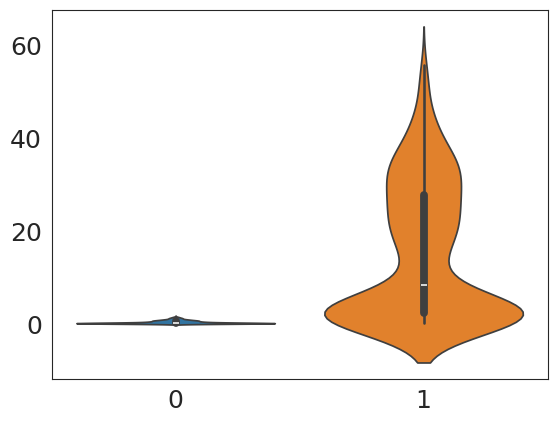

In [71]:
sns.violinplot([all_differences, all_rand_differences])

<Axes: >

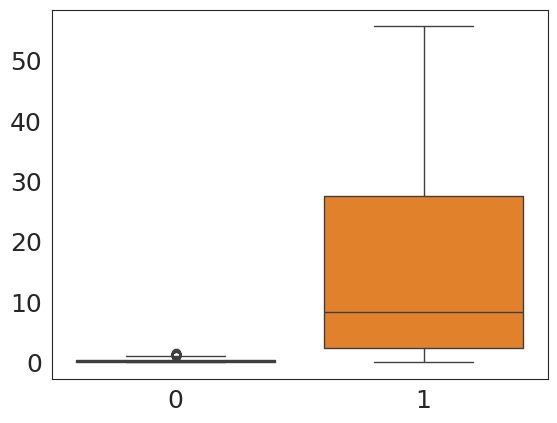

In [70]:
sns.boxplot([all_differences, all_rand_differences])

<Axes: ylabel='Count'>

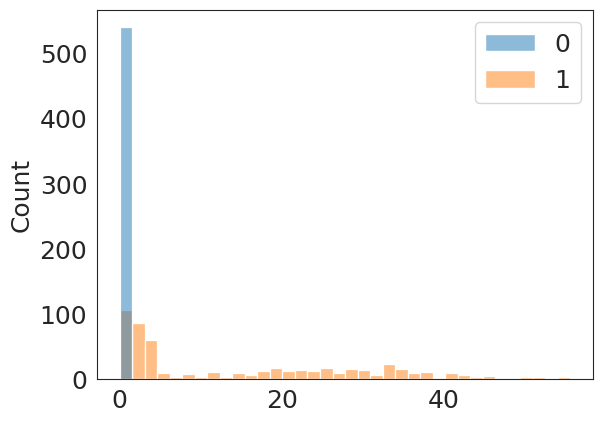

In [72]:
sns.histplot([all_differences, all_rand_differences])

In [65]:
#as a control we plot the mean distances between some randomly picked graphs

# mean and std (over all graphs) for l2 distance in difference seeds to the mean curve
avg_rand_differences = []
std_rand_differneces = []
all_rand_differences = []
for seed_i in range(n_seeds):
    # getting a difference between the curves from random seed
    l2_differences = []
    
    for graph_index in df_mean_curve.index:
        other_graph = np.random.choice(np.delete(list(df_mean_curve.index),graph_index))
        this_curve, other_curve = mag_funs_per_seed[seed_i].loc[graph_index], df_mean_curve.loc[other_graph]
        l2norm = np.linalg.norm([this_curve - other_curve], ord=None)
        l2_differences.append(l2norm)
        all_rand_differences.append(l2norm)
    avg_rand_differences.append(np.mean(l2_differences))
    std_rand_differneces.append(np.std(l2_differences))

In [56]:
np.random.choice(np.delete(list(df_mean_curve.index),graph_index))

129

In [ ]:
# comparing difference in accuracies 
res_df

In [76]:
(np.mean(avg_differences))

0.33395246990124344

In [73]:
np.mean(all_differences)

0.3339524699012434

# Results

## stability one curve 

stability of the random edge process. We set `n_reps=1` (only do the random edge contraction once) then we repeat this over different seeds (seed_stability.py with n_reps = 1, n_seeds = 10) 

In [4]:
res_dir = 'simulations/results/ablations/seed_stability/n_seeds10_nresps_1'


In [5]:
all_diffs = pd.read_csv(f'{res_dir}/all_diffs.csv', index_col=0)
avg_curve_diffs = pd.read_csv(f'{res_dir}/avg_curve_diffs.csv', index_col=0)
std_curve_diffs = pd.read_csv(f'{res_dir}/std_curve_diffs.csv', index_col=0)
all_rand_diffs = pd.read_csv(f'{res_dir}/all_rand_diffs.csv', index_col=0)
avg_rand_diffs = pd.read_csv(f'{res_dir}/avg_rand_diffs.csv', index_col=0)
std_rand_diffs = pd.read_csv(f'{res_dir}/std_rand_diffs.csv', index_col=0)
# res = pd.read_csv(f'{res_dir}/results_combined.csv', index_col=0, header=[0,1])
avg_accs = pd.read_csv(f'{res_dir}/avg_accs.csv', index_col=[0,1], header=0)
avg_accs = avg_accs.transpose()


(array([1, 2, 3, 4, 5, 6, 7, 8]),
 [Text(1, 0, '(ER, divcurves_shortest_path_distance)'),
  Text(2, 0, '(ER, divcurves_pca_shortest_path_distance)'),
  Text(3, 0, '(SBM, divcurves_shortest_path_distance)'),
  Text(4, 0, '(SBM, divcurves_pca_shortest_path_distance)'),
  Text(5, 0, '(RG, divcurves_shortest_path_distance)'),
  Text(6, 0, '(RG, divcurves_pca_shortest_path_distance)'),
  Text(7, 0, '(RPG, divcurves_shortest_path_distance)'),
  Text(8, 0, '(RPG, divcurves_pca_shortest_path_distance)')])

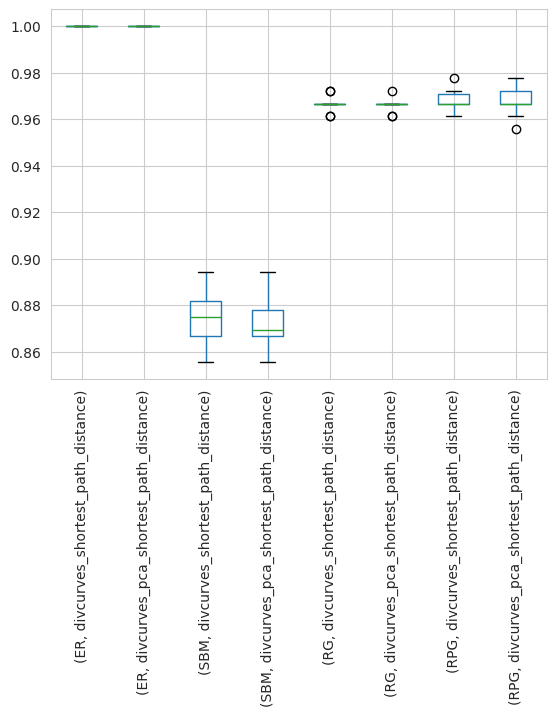

In [20]:
avg_accs.boxplot()
plt.xticks(rotation=90)


In [21]:
#standard deviation over the mean accuracies
avg_accs.apply(np.std, axis=0)

ER   divcurves_shortest_path_distance        0.000000
     divcurves_pca_shortest_path_distance    0.000000
SBM  divcurves_shortest_path_distance        0.011125
     divcurves_pca_shortest_path_distance    0.010830
RG   divcurves_shortest_path_distance        0.003514
     divcurves_pca_shortest_path_distance    0.002992
RPG  divcurves_shortest_path_distance        0.004843
     divcurves_pca_shortest_path_distance    0.006597
dtype: float64

In [14]:
all_diffs.index

Index(['ER', 'SBM', 'RG', 'RPG'], dtype='object')

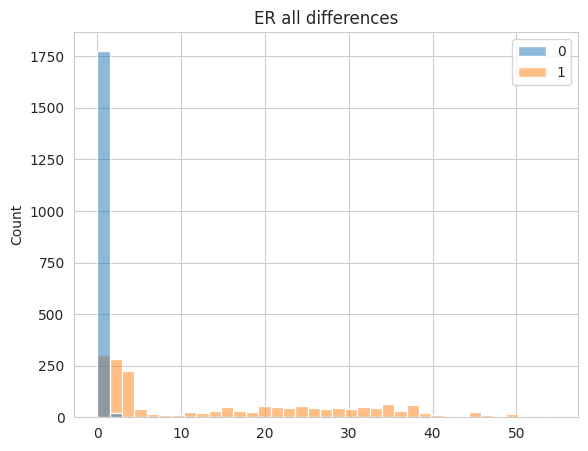

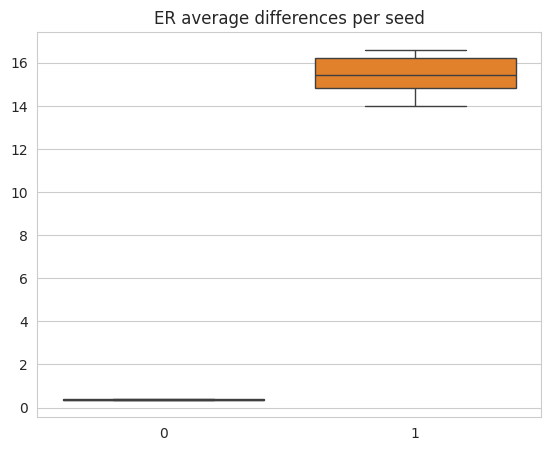

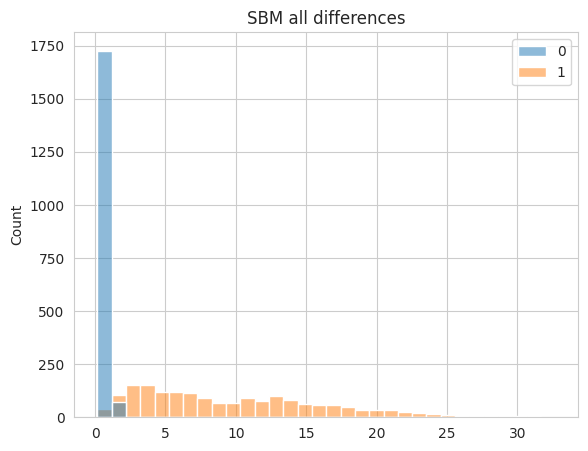

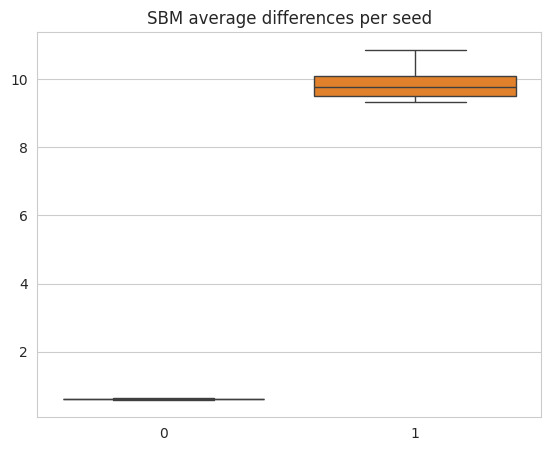

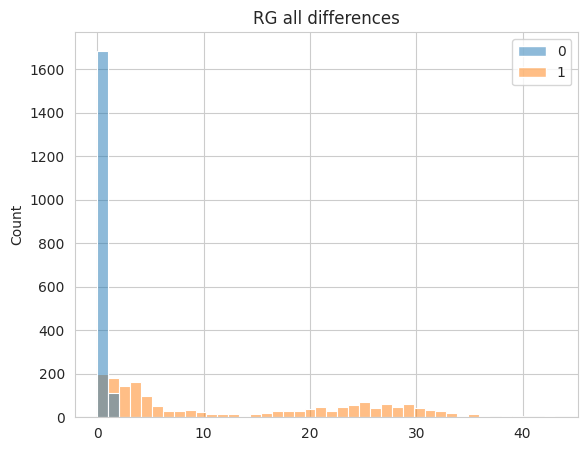

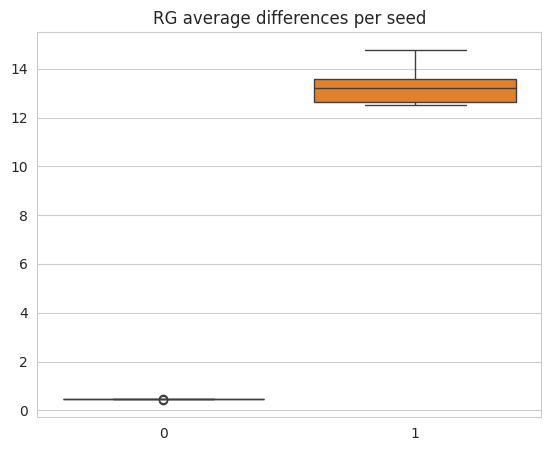

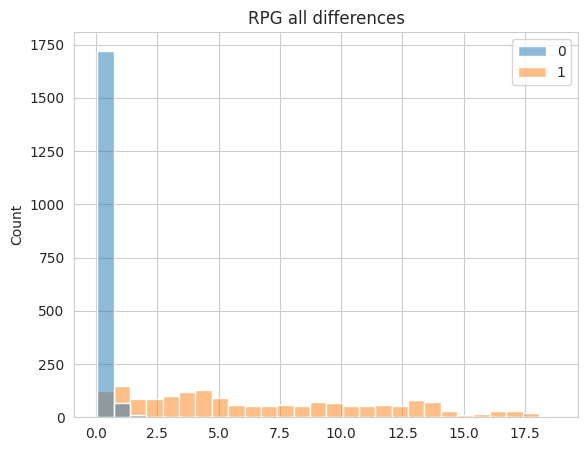

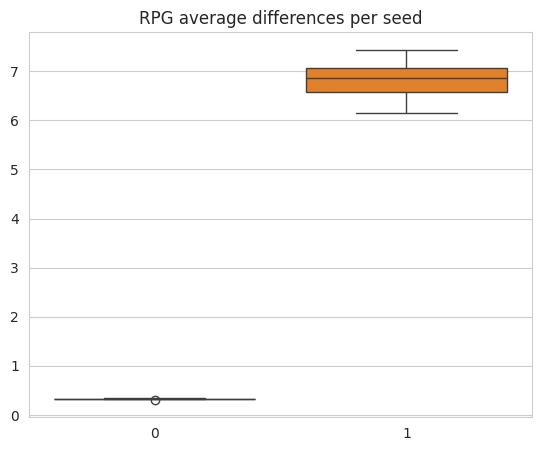

In [25]:
for model in all_diffs.index:
    # plotting all differences, so n_seeds*len(G_nx) differences, between the 
    # curves from different seeds and the mean curve over all seeds
    all_diffs_model = list(all_diffs.loc[model])
    all_rand_diffs_model = list(all_rand_diffs.loc[model])

    fig, ax = plt.subplots(ncols=1, nrows=1, figsize=(6.5,5))
    # sns.violinplot([all_diffs_model, all_rand_diffs_model])
    sns.histplot([all_diffs_model, all_rand_diffs_model])
    ax.set_title(f'{model} all differences')
    # sns.boxplot([all_diffs_model, all_rand_diffs_model])

    #plotting the average mean distance over all graphs per seed, control rand is if we compare a graph to a randomly chosen other graph in the mean curve
    avg_diffs_model = list(avg_curve_diffs.loc[model])
    avg_rand_diffs_model = list(avg_rand_diffs.loc[model])

    fig, ax = plt.subplots(ncols=1, nrows=1, figsize=(6.5,5))
    # sns.violinplot([avg_diffs_model, avg_rand_diffs_model])
    # sns.histplot([avg_diffs_model, avg_rand_diffs_model])
    sns.boxplot([avg_diffs_model, avg_rand_diffs_model])
    ax.set_title(f'{model} average differences per seed')
    